In [59]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import models, layers

In [60]:
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

In [61]:
from pathlib import Path
train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
    directory=str(Path.home() / ".cache" / "ml-notebooks" / "speech-commands"),
    seed=seed,
    validation_split=0.3,
    output_sequence_length=16000,
    batch_size=64,
    subset='both'
)

Found 6505 files belonging to 4 classes.
Using 4554 files for training.
Using 1951 files for validation.


In [62]:
label = np.array(train_ds.class_names)
print(label)

['follow' 'learn' 'tree' 'visual']


In [63]:
def squeeze(audio, label):
    audio = tf.squeeze(audio, axis=-1)
    return audio, label

def get_st(waveform):
    st = tf.signal.stft(waveform, frame_length=255, frame_step=128)
    st = tf.abs(st)
    st = st[..., tf.newaxis]
    return st

def make_st_ds(ds):
    return ds.map(
        lambda i, j: (get_st(i), j),
        tf.data.AUTOTUNE
    )

In [64]:
train_ds = train_ds.map(squeeze, tf.data.AUTOTUNE)
val_ds = val_ds.map(squeeze, tf.data.AUTOTUNE)

test_ds = val_ds.shard(num_shards=2, index=0)
val_ds = val_ds.shard(num_shards=2, index=1)

In [65]:
train_st_ds = make_st_ds(train_ds)
val_st_ds = make_st_ds(val_ds)
test_st_ds = make_st_ds(test_ds)

In [66]:
for i, j in train_st_ds.take(1):
    break

input_shape = i.shape[1:]
label_len = len(label)

# print(input_shape)
# print(label_len)

In [67]:
norm_layer = layers.Normalization()
norm_layer.adapt(
    data=train_st_ds.map(
        lambda i, j: i
    )
)

In [68]:
model = models.Sequential([
    layers.Input(input_shape),
    layers.Resizing(32, 32),
    norm_layer,
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.5),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(label_len)
])

In [69]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing_2 (Resizing)       (None, 32, 32, 1)         0         
                                                                 
 normalization_1 (Normalizat  (None, 32, 32, 1)        3         
 ion)                                                            
                                                                 
 conv2d_4 (Conv2D)           (None, 30, 30, 64)        640       
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 15, 15, 64)       0         
 2D)                                                             
                                                                 
 conv2d_5 (Conv2D)           (None, 13, 13, 128)       73856     
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 6, 6, 128)       

In [70]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [71]:
history = model.fit(
    train_st_ds,
    validation_data=val_st_ds,
    epochs=10,
    callbacks=tf.keras.callbacks.EarlyStopping(verbose=1, patience=2)
)

Epoch 1/10
72/72 [==============================] - 3s 41ms/step - loss: 0.8572 - accuracy: 0.6682 - val_loss: 0.5680 - val_accuracy: 0.7677
Epoch 2/10
72/72 [==============================] - 3s 39ms/step - loss: 0.5242 - accuracy: 0.8210 - val_loss: 0.3521 - val_accuracy: 0.8865
Epoch 3/10
72/72 [==============================] - 3s 40ms/step - loss: 0.3919 - accuracy: 0.8663 - val_loss: 0.2889 - val_accuracy: 0.8958
Epoch 4/10
72/72 [==============================] - 3s 40ms/step - loss: 0.3228 - accuracy: 0.8898 - val_loss: 0.2474 - val_accuracy: 0.9125
Epoch 5/10
72/72 [==============================] - 3s 40ms/step - loss: 0.2704 - accuracy: 0.9082 - val_loss: 0.2353 - val_accuracy: 0.9281
Epoch 6/10
72/72 [==============================] - 3s 39ms/step - loss: 0.2324 - accuracy: 0.9231 - val_loss: 0.1786 - val_accuracy: 0.9396
Epoch 7/10
72/72 [==============================] - 3s 39ms/step - loss: 0.2163 - accuracy: 0.9251 - val_loss: 0.1611 - val_accuracy: 0.9438
Epoch 8/10
72

In [72]:
for i, (spec_batch, lab_batch) in enumerate(test_st_ds):
    pred = model.predict(spec_batch)

    for j in range(len(lab_batch)):
        t = lab_batch[j].numpy()
        p = np.argmax(pred[j])
        print(f'Data {j}: Original Label -> {label[t]}, Prediction -> {label[p]}')

2/2 [==============================] - 0s 9ms/step
Data 0: Original Label -> tree, Prediction -> tree
Data 1: Original Label -> learn, Prediction -> learn
Data 2: Original Label -> tree, Prediction -> tree
Data 3: Original Label -> follow, Prediction -> follow
Data 4: Original Label -> tree, Prediction -> tree
Data 5: Original Label -> follow, Prediction -> follow
Data 6: Original Label -> follow, Prediction -> follow
Data 7: Original Label -> follow, Prediction -> follow
Data 8: Original Label -> follow, Prediction -> follow
Data 9: Original Label -> learn, Prediction -> learn
Data 10: Original Label -> visual, Prediction -> visual
Data 11: Original Label -> learn, Prediction -> learn
Data 12: Original Label -> tree, Prediction -> tree
Data 13: Original Label -> follow, Prediction -> follow
Data 14: Original Label -> follow, Prediction -> follow
Data 15: Original Label -> tree, Prediction -> tree
Data 16: Original Label -> learn, Prediction -> learn
Data 17: Original Label -> follow, 

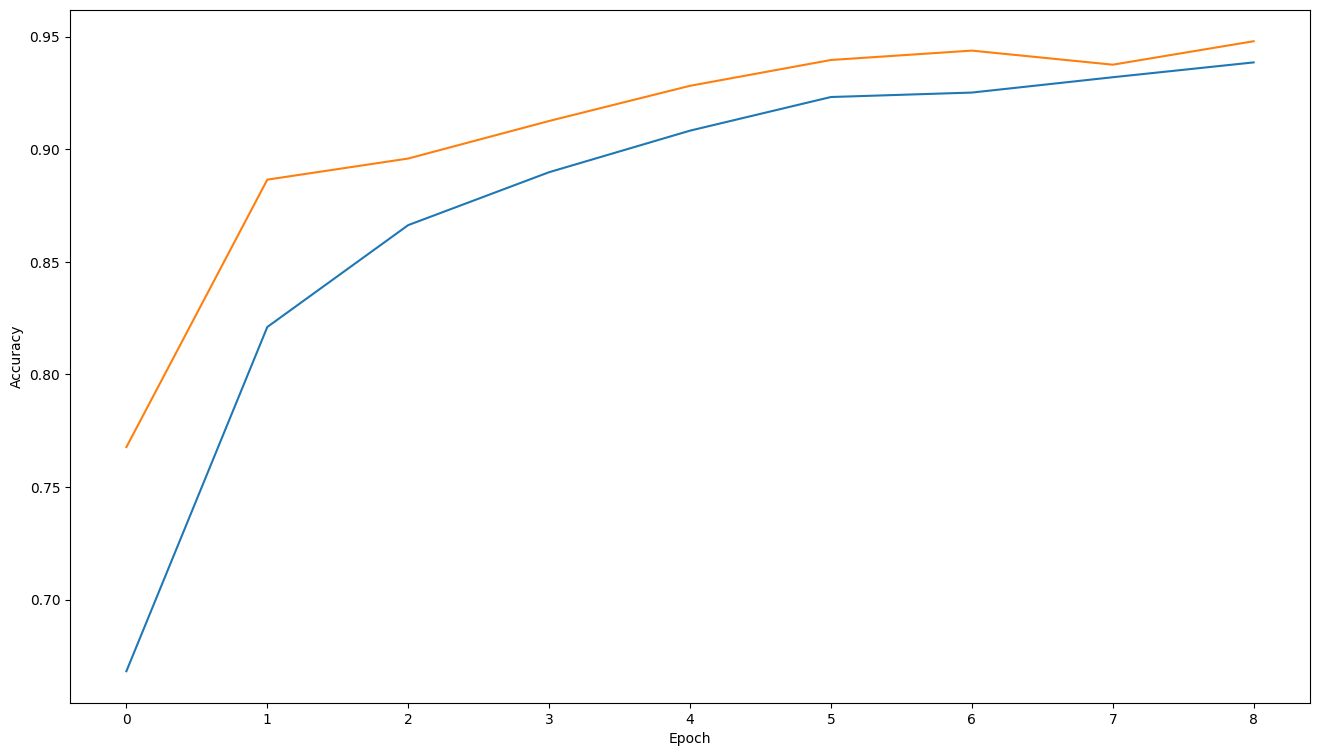

In [73]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epoch_num = range(len(acc))

plt.figure(figsize=(16, 9))
plt.plot(epoch_num, acc)
plt.plot(epoch_num, val_acc)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()